In [73]:
import torch
import matplotlib.pyplot as plt 
import matplotlib.ticker as ticker 
import math

# Autograd in Pytorch

In [74]:
a= torch.linspace(start=0. ,end=2. * math.pi, steps=25,requires_grad=True)
print(a)

tensor([0.0000, 0.2618, 0.5236, 0.7854, 1.0472, 1.3090, 1.5708, 1.8326, 2.0944,
        2.3562, 2.6180, 2.8798, 3.1416, 3.4034, 3.6652, 3.9270, 4.1888, 4.4506,
        4.7124, 4.9742, 5.2360, 5.4978, 5.7596, 6.0214, 6.2832],
       requires_grad=True)


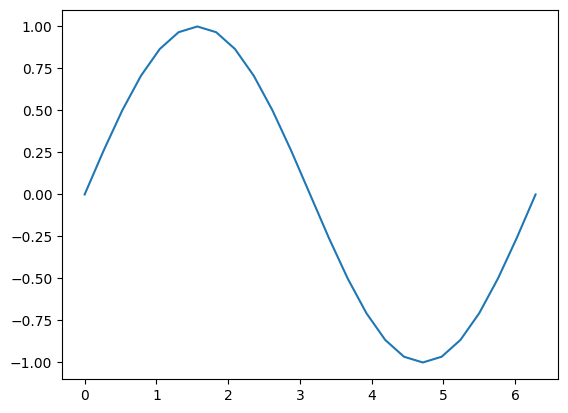

In [75]:
b= torch.sin(a)
plt.plot(a.detach(), b.detach())

In [76]:
print(b)

tensor([ 0.0000e+00,  2.5882e-01,  5.0000e-01,  7.0711e-01,  8.6603e-01,
         9.6593e-01,  1.0000e+00,  9.6593e-01,  8.6603e-01,  7.0711e-01,
         5.0000e-01,  2.5882e-01, -8.7423e-08, -2.5882e-01, -5.0000e-01,
        -7.0711e-01, -8.6603e-01, -9.6593e-01, -1.0000e+00, -9.6593e-01,
        -8.6603e-01, -7.0711e-01, -5.0000e-01, -2.5882e-01,  1.7485e-07],
       grad_fn=<SinBackward0>)


In [77]:
c= b*2
print(c)

d= c-1
print(d)

tensor([ 0.0000e+00,  5.1764e-01,  1.0000e+00,  1.4142e+00,  1.7321e+00,
         1.9319e+00,  2.0000e+00,  1.9319e+00,  1.7321e+00,  1.4142e+00,
         1.0000e+00,  5.1764e-01, -1.7485e-07, -5.1764e-01, -1.0000e+00,
        -1.4142e+00, -1.7321e+00, -1.9319e+00, -2.0000e+00, -1.9319e+00,
        -1.7321e+00, -1.4142e+00, -1.0000e+00, -5.1764e-01,  3.4969e-07],
       grad_fn=<MulBackward0>)
tensor([-1.0000e+00, -4.8236e-01,  0.0000e+00,  4.1421e-01,  7.3205e-01,
         9.3185e-01,  1.0000e+00,  9.3185e-01,  7.3205e-01,  4.1421e-01,
         1.1921e-07, -4.8236e-01, -1.0000e+00, -1.5176e+00, -2.0000e+00,
        -2.4142e+00, -2.7321e+00, -2.9319e+00, -3.0000e+00, -2.9319e+00,
        -2.7321e+00, -2.4142e+00, -2.0000e+00, -1.5176e+00, -1.0000e+00],
       grad_fn=<SubBackward0>)


In [78]:
out= d.sum()
print(out)

tensor(-25., grad_fn=<SumBackward0>)


In [79]:
print('d:')
print(d.grad_fn)
print(d.grad_fn.next_functions)
print(d.grad_fn.next_functions[0][0].next_functions)
print(d.grad_fn.next_functions[0][0].next_functions[0][0].next_functions)
print(d.grad_fn.next_functions[0][0].next_functions[0][0].next_functions[0][0].next_functions)
print('\nc:')
print(c.grad_fn)
print('\nb:')
print(b.grad_fn)
print('\na:')
print(a.grad_fn)

d:
((<MulBackward0 object at 0x11b81ae50>, 0), (None, 0))
((<SinBackward0 object at 0x11b81afd0>, 0), (None, 0))
((<AccumulateGrad object at 0x11b81af10>, 0),)
()

c:

b:

a:
None


tensor([ 2.0000e+00,  1.9319e+00,  1.7321e+00,  1.4142e+00,  1.0000e+00,
         5.1764e-01, -8.7423e-08, -5.1764e-01, -1.0000e+00, -1.4142e+00,
        -1.7321e+00, -1.9319e+00, -2.0000e+00, -1.9319e+00, -1.7321e+00,
        -1.4142e+00, -1.0000e+00, -5.1764e-01,  2.3850e-08,  5.1764e-01,
         1.0000e+00,  1.4142e+00,  1.7321e+00,  1.9319e+00,  2.0000e+00])


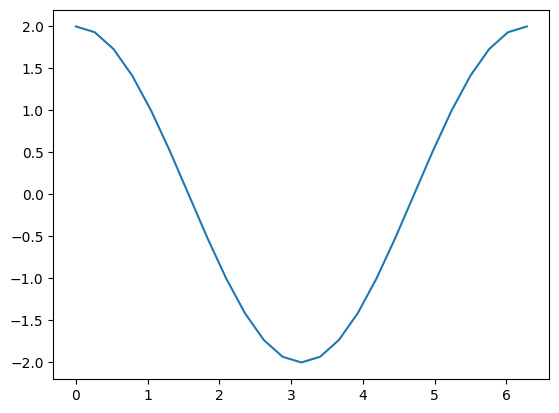

In [80]:

out.backward()
print(a.grad)

plt.plot(a.detach(), a.grad.detach())

# Autograd in training loop

In [81]:
BATCH_SIZE=16
DIM_IN=1000
HIDDEN_SIZE=100
DIM_OUT=10


class TinyModel(torch.nn.Module):
    def __init__(self):
        super(TinyModel, self).__init__()

        self.layer1= torch.nn.Linear(DIM_IN, HIDDEN_SIZE)
        self.relu= torch.nn.ReLU()
        self.layer2= torch.nn.Linear(HIDDEN_SIZE, DIM_OUT)

    def forward(self, x):
        x= self.layer1(x)
        x= self.relu(x)
        x= self.layer2(x)
        return x

some_input = torch.randn(BATCH_SIZE, DIM_IN, requires_grad=False)
ideal_output = torch.randn(BATCH_SIZE, DIM_OUT, requires_grad=False)

model= TinyModel()


In [82]:
print(model.layer2.weight[0][0:10])
print(model.layer2.weight.grad)

tensor([ 0.0462,  0.0449, -0.0127,  0.0986,  0.0466,  0.0582, -0.0046, -0.0473,
        -0.0114, -0.0869], grad_fn=<SliceBackward0>)
None


In [83]:
optimizer=torch.optim.SGD(model.parameters(), lr=0.001)
prediction= model(some_input)
loss= (ideal_output-prediction).pow(2).sum()
print(loss)

tensor(174.9540, grad_fn=<SumBackward0>)


In [84]:
loss.backward()
print(model.layer2.weight[0][0:10])
print(model.layer2.weight.grad[0][0:10])

tensor([ 0.0462,  0.0449, -0.0127,  0.0986,  0.0466,  0.0582, -0.0046, -0.0473,
        -0.0114, -0.0869], grad_fn=<SliceBackward0>)
tensor([ 0.7265,  1.8908,  5.4419,  2.2106,  0.2613, -0.2663,  1.8268, -0.5771,
         5.0928,  0.7108])


In [85]:
optimizer.step()
print(model.layer2.weight[0][0:10])
print(model.layer2.weight.grad[0][0:10])

tensor([ 0.0455,  0.0431, -0.0181,  0.0963,  0.0464,  0.0585, -0.0065, -0.0467,
        -0.0165, -0.0876], grad_fn=<SliceBackward0>)
tensor([ 0.7265,  1.8908,  5.4419,  2.2106,  0.2613, -0.2663,  1.8268, -0.5771,
         5.0928,  0.7108])


One important thing about the process: After calling `optimizer.step()`, you need to call `optimizer.zero_grad()`, or else every time you run `loss.backward()`, the gradients on the learning weights will accumulate:

In [88]:
# print(model.layer2.weight.grad[0][0:10])

for i in range(0, 5):
    prediction = model(some_input)
    loss = (ideal_output - prediction).pow(2).sum()
    loss.backward()
    
print(model.layer2.weight.grad[0][0:10])

optimizer.zero_grad()

# print(model.layer2.weight.grad[0][0:10])

tensor([ 0.0268, -3.9219, 17.6106, -3.5384, -3.8578, -1.0887,  4.9486, -3.4490,
         7.9221, -0.3428])


# Turning out Autograd

In [89]:
a= torch.ones(2,3 ,requires_grad=True)
print(a)
b1= a*2
print(b1)
a.requires_grad=False

b2= a*2
print(b2)


tensor([[1., 1., 1.],
        [1., 1., 1.]], requires_grad=True)
tensor([[2., 2., 2.],
        [2., 2., 2.]], grad_fn=<MulBackward0>)
tensor([[2., 2., 2.],
        [2., 2., 2.]])


In [90]:
a= torch.ones(2,3, requires_grad=True) *2
b= torch.ones(2,3, requires_grad=True)*3

c= a+b
print(c)

with torch.no_grad():
    c2= a+b

print(c2)

c3= a+b
print(c3)

tensor([[5., 5., 5.],
        [5., 5., 5.]], grad_fn=<AddBackward0>)
tensor([[5., 5., 5.],
        [5., 5., 5.]])
tensor([[5., 5., 5.],
        [5., 5., 5.]], grad_fn=<AddBackward0>)


In [92]:
def tensor1(x, y):
    return x+y

@torch.no_grad()
def tensor2(x,y):
    return x+y


a= torch.ones(2,3, requires_grad=True) *2
b= torch.ones(2,3, requires_grad=True)*3

print(tensor1(a, b))
print(tensor2(a,b))

tensor([[5., 5., 5.],
        [5., 5., 5.]], grad_fn=<AddBackward0>)
tensor([[5., 5., 5.],
        [5., 5., 5.]])


In [94]:
a= torch.rand(2,3 ,requires_grad=True)
b= a.detach()
print(a)
print(b)

tensor([[0.4057, 0.7402, 0.9793],
        [0.9697, 0.4625, 0.8021]], requires_grad=True)
tensor([[0.4057, 0.7402, 0.9793],
        [0.9697, 0.4625, 0.8021]])


In place operation, give you run time error, because is it destroying the history of the tensor

In [96]:
a= torch.rand(2,3 , requires_grad=True)
# torch.sin_(a)

# Autograd profile

In [100]:
device= torch.device("cpu")
run_on_mps= False

if torch.backends.mps.is_available():
    device= torch.device("mps")
    run_on_mps=True

print(device)
x= torch.randn(2,3, requires_grad=True)
y= torch.rand(2,3, requires_grad=True)
z= torch.ones(2,3, requires_grad=True)

with torch.autograd.profiler.profile(use_device=device) as prf:
    for _ in range(100):
        z=(z/x)*y

print(prf.key_averages().table())

mps
-------------  ------------  ------------  ------------  ------------  ------------  ------------  
         Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg    # of Calls  
-------------  ------------  ------------  ------------  ------------  ------------  ------------  
    aten::div        57.32%     187.986us        57.32%     187.986us       1.880us           100  
    aten::mul        42.68%     139.995us        42.68%     139.995us       1.400us           100  
-------------  ------------  ------------  ------------  ------------  ------------  ------------  
Self CPU time total: 327.981us



/Users/saleh/Desktop/Pytorch/Codes/pytorch/venv/lib/python3.9/site-packages/torch/autograd/profiler.py:263: UserWarning: The mps is not a valid device option.
  warn(f"The {self.use_device} is not a valid device option.")
